# Airbnb Price Classification: Logistic Regression vs Neural Network

Break Through Tech AI capstone project. This notebook compares a logistic regression classifier with a feedforward neural network for predicting whether NYC Airbnb listings are in the top 25% of prices.

**Data:** 28,022 Airbnb NYC listings. The original course dataset (`data_capstone/airbnbListingsData.csv`) is required to rerun this notebook and is not included. Saved notebook outputs reflect the original run.

**Caution:** The dataset is imbalanced. Additionally, missing-value imputation and one-hot encoding in this original notebook happen before train/test splitting; in a future revision, these should be fitted using training data only to avoid leakage.

## Setup and load data

In [1]:
import pandas as pd
import numpy as np
import os 
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
import tensorflow.keras as keras
from sklearn.preprocessing import StandardScaler
import time

In [ ]:
# File paths for both data sets
airbnb_filename = os.path.join("data", "airbnbListingsData.csv")
# Load your chosen dataset and save it to df
df = pd.read_csv(airbnb_filename, header=0)

df.head()

,name,description,neighborhood_overview,host_name,host_location,host_about,host_response_rate,host_acceptance_rate,host_is_superhost,host_listings_count,...,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,n_host_verifications,price_category
0,Skylit Midtown Castle,"Beautiful, spacious skylit studio in the heart...",Centrally located in the heart of Manhattan ju...,Jennifer,"New York, New York, United States",A New Yorker since 2000! My passion is creatin...,0.80,0.17,True,8.0,...,4.86,4.41,False,3,3,0,0,0.33,9,low
1,"Whole flr w/private bdrm, bath & kitchen(pls r...","Enjoy 500 s.f. top floor in 1899 brownstone, w...",Just the right mix of urban center and local n...,LisaRoxanne,"New York, New York, United States",Laid-back Native New Yorker (formerly bi-coast...,0.09,0.69,True,1.0,...,4.71,4.64,False,1,1,0,0,4.86,6,low
2,"Spacious Brooklyn Duplex, Patio + Garden",We welcome you to stay in our lovely 2 br dupl...,NaN,Rebecca,"Brooklyn, New York, United States","Rebecca is an artist/designer, and Henoch is i...",1.00,0.25,True,1.0,...,4.50,5.00,False,1,1,0,0,0.02,3,high
3,Large Furnished Room Near B'way,Please don’t expect the luxury here just a bas...,"Theater district, many restaurants around here.",Shunichi,"New York, New York, United States",I used to work for a financial industry but no...,1.00,1.00,True,1.0,...,4.87,4.36,False,1,0,1,0,3.68,4,low
4,Cozy Clean Guest Room - Family Apt,"Our best guests are seeking a safe, clean, spa...",Our neighborhood is full of restaurants and ca...,MaryEllen,"New York, New York, United States",Welcome to family life with my oldest two away...,NaN,NaN,True,1.0,...,4.94,4.92,False,1,0,1,0,0.87,7,low


## Prediction task and feature selection

1. I chose the Airbnb listing data set.
2. The label would be "price_category" predicting wether the listing is high price or low price. The model will be a binary classification model.
3. I plan to use listing, host, and review characteristics as predictor variables while excluding the target variable (price_category). These features include the listing description, neighborhood information, host characteristics (such as host response rate, host acceptance rate, superhost status, and number of listings), property characteristics (such as room type, accommodates, bathrooms, bedrooms, beds, and amenities), location information, review scores, number of reviews, availability, instant booking status, and the number of host verifications. During data exploration, I may remove features with excessive missing values or features that are not useful for prediction later on.
4. Predicting whether an Airbnb listing is likely to be high-priced or low-priced can help Airbnb hosts make informed pricing decisions and better understand the factors that influence listing value. It can also help Airbnb recommend competitive prices to new hosts, identify listings that may be underpriced or overpriced, and provide useful market insights. 

## Exploratory data analysis

low     20785
high     7237
Name: price_category, dtype: int64


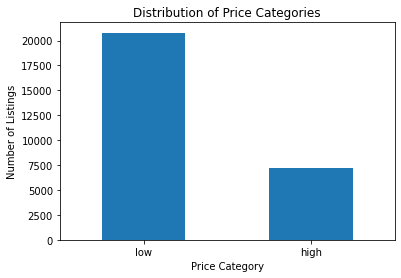

In [3]:
class_counts = df['price_category'].value_counts()

print(class_counts)

# Plot the class distribution
plt.figure(figsize=(6,4))
class_counts.plot(kind='bar')

plt.title('Distribution of Price Categories')
plt.xlabel('Price Category')
plt.ylabel('Number of Listings')
plt.xticks(rotation=0)

plt.show()

In [4]:
df.dtypes

name                                             object
description                                      object
neighborhood_overview                            object
host_name                                        object
host_location                                    object
host_about                                       object
host_response_rate                              float64
host_acceptance_rate                            float64
host_is_superhost                                  bool
host_listings_count                             float64
host_total_listings_count                       float64
host_has_profile_pic                               bool
host_identity_verified                             bool
neighbourhood_group_cleansed                     object
room_type                                        object
accommodates                                      int64
bathrooms                                       float64
bedrooms                                        

In [5]:
df.describe()

,host_response_rate,host_acceptance_rate,host_listings_count,host_total_listings_count,accommodates,bathrooms,bedrooms,beds,price,minimum_nights,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,n_host_verifications
count,16179.000000,16909.000000,28022.000000,28022.000000,28022.000000,28022.000000,25104.000000,26668.000000,28022.000000,28022.000000,...,28022.000000,28022.000000,28022.000000,28022.000000,28022.000000,28022.000000,28022.000000,28022.000000,28022.000000,28022.000000
mean,0.906901,0.791953,14.554778,14.554778,2.874491,1.142174,1.329708,1.629556,154.228749,18.689387,...,4.814300,4.808041,4.750393,4.647670,9.581900,5.562986,3.902077,0.048283,1.758325,5.169510
std,0.227282,0.276732,120.721287,120.721287,1.860251,0.421132,0.700726,1.097104,140.816605,25.569151,...,0.438603,0.464585,0.415717,0.518023,32.227523,26.121426,17.972386,0.442459,4.446143,2.028497
min,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,29.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.010000,1.000000
25%,0.940000,0.680000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,70.000000,2.000000,...,4.810000,4.810000,4.670000,4.550000,1.000000,0.000000,0.000000,0.000000,0.130000,4.000000
50%,1.000000,0.910000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,115.000000,30.000000,...,4.960000,4.970000,4.880000,4.780000,1.000000,1.000000,0.000000,0.000000,0.510000,5.000000
75%,1.000000,1.000000,3.000000,3.000000,4.000000,1.000000,1.000000,2.000000,180.000000,30.000000,...,5.000000,5.000000,5.000000,5.000000,3.000000,1.000000,1.000000,0.000000,1.830000,7.000000
max,1.000000,1.000000,3387.000000,3387.000000,16.000000,8.000000,12.000000,21.000000,1000.000000,1250.000000,...,5.000000,5.000000,5.000000,5.000000,421.000000,308.000000,359.000000,8.000000,141.000000,13.000000


In [6]:
#missing values
df.isnull().sum().sort_values(ascending=False)

host_response_rate                              11843
host_acceptance_rate                            11113
host_about                                      10945
neighborhood_overview                            9816
bedrooms                                         2918
beds                                             1354
description                                       570
host_location                                      60
name                                                5
accommodates                                        0
maximum_nights                                      0
minimum_nights                                      0
price                                               0
amenities                                           0
bathrooms                                           0
host_has_profile_pic                                0
room_type                                           0
neighbourhood_group_cleansed                        0
host_identity_verified      

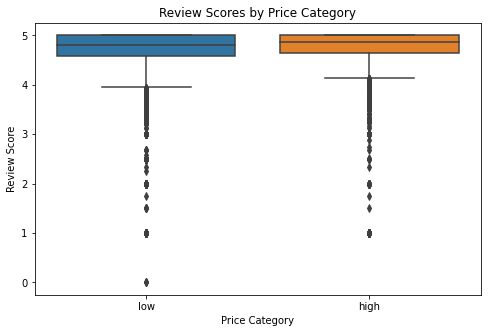

In [7]:
#one plot that visualizes a relationship between features and the label.
plt.figure(figsize=(8,5))

sns.boxplot(
    x='price_category',
    y='review_scores_rating',
    data=df
)

plt.title('Review Scores by Price Category')
plt.xlabel('Price Category')
plt.ylabel('Review Score')

plt.show()

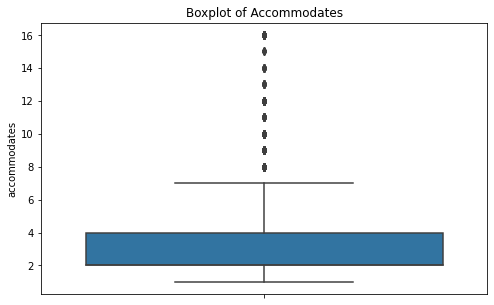

In [8]:
#outliers
plt.figure(figsize=(8,5))

sns.boxplot(y=df['accommodates'])

plt.title('Boxplot of Accommodates')

plt.show()

This dataset contains different features including the numerical, categorical, text and Boolean features. Several variables have substantial missing values, particularly host_response_rate, host_acceptance_rate, host_about, and neighborhood_overview. These missing values will need to be handled by either imputing numerical values or removing them if they are not essential for prediction.

The boxplot also indicated outliers, for example the accommodates feature contains a small number of listings that accommodate many more guests than typical listings. Since the model is sensetive to extreme values, the unusual listing might influence its performance. 

The boxplot comparing review_scores_rating and price_category shows that both high-priced and low-priced listings generally receive high review scores. This suggests that review scores alone are unlikely to strongly distinguish between the two price categories, but they may still contribute useful information when combined with other features.

For data preparation, I plan to handle missing values appropriately, encode categorical variables using one-hot encoding, convert Boolean variables into numeric values, remove unnecessary text features that are unlikely to improve prediction, and scale the numerical features if I use models such as K-Nearest Neighbors or Logistic Regression. Because the dataset contains more low-priced than high-priced listings, I will use a stratified train-test split and evaluate model performance using metrics such as accuracy and F1.

## Fairness and ethical considerations

1. One potential source of bias in this dataset is that it only includes Airbnb listings in New York City, so the model may not generalize well to listings in other cities or countries. In  addition the dataset contains Airbnb listings from New York City and was likely collected from information supplied by hosts and activity recorded on the Airbnb platform. Therefore, it represents people who use Airbnb and does not represent the entire housing market. Historical prices may already reflect inequalities in neighborhood investment, tourism demand and discrimination. Features such as neighborhood, location, room type, and availability may serve as proxies for socioeconomic status and, indirectly, race or ethnicity because residential patterns in New York City are not evenly distributed.
2. Incorrect predictions could negatively affect both Airbnb hosts and guests. If the model incorrectly predicts that a listing should be high-priced, a host may overprice the property and receive fewer bookings.  New hosts or hosts in less expensive neighborhoods may be especially affected if the model systematically underestimates their listings based on historical pricing patterns. For guests if a lot of listings are overpriced they would't be able to find a one that is in their budget, or if they are underpriced there would be too much demand for them, leaving many guests unsutisfied. 

## Data preparation

In [9]:
df_model = df.copy()

#converting the label to binary
condition1 = (df_model['price_category'] == 'high')
df_model['price_category'] = np.where(condition1, 1, 0)

#drop the useless text columns
text_cols = [
    'name',
    'description',
    'neighborhood_overview',
    'host_name',
    'host_location',
    'host_about',
    'amenities',
    'price'
    
]

df_model = df_model.drop(columns=text_cols)

#fill missing numerical values with the median
numeric_cols = df_model.select_dtypes(include=['int64','float64']).columns

for col in numeric_cols:
    df_model[col] = df_model[col].fillna(df_model[col].median())

#fill missing categorical values with the mode
categorical_cols = df_model.select_dtypes(include=['object','bool']).columns

for col in categorical_cols:
    df_model[col] = df_model[col].fillna(df_model[col].mode()[0])

#one-hot encode categorical variables
bool_cols = df_model.select_dtypes(include='bool').columns
df_model[bool_cols] = df_model[bool_cols].astype(int)
df_model = pd.get_dummies(df_model, drop_first=True)


To prepare the data for modeling, I first converted the target variable, price_category, into a binary numeric label, where 0 represents a low-priced listing and 1 represents a high-priced listing.

Next, I removed several text-based features, including name, description, neighborhood_overview, host_name, host_location, host_about, and amenities because they would require natural language processing. I also removed the price feature because price_category was created directly from the listing price. Including price would give the model information that directly determines the label and would cause data leakage, producing unrealistically high performance.

To handle missing numerical values, I replaced them with the median of each feature. The median was chosen because it is less affected by outliers than the mean. For categorical and Boolean variables, I replaced missing values with the most frequent value.

Then I applied one-hot encoding to all categorical features.

Finally, I will scale in the next cells the feature values using StandardScaler. Scaling is particularly important for models such as K-Nearest Neighbors, and Logistic Regression, because these models are sensitive to the scale of the input features. Standardizing the data ensures that variables with larger numerical ranges do not dominate the learning process. 

## Logistic regression and hyperparameter tuning

In [10]:
# Create labeled examples from the dataset
#separate features and label
X = df_model.drop(columns='price_category')
y = df_model['price_category']

In [11]:
# Create training and test sets out of the labeled examples 
#train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=1234, stratify=y)

In [12]:
# Scale the data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
# Train, test and evaluate your model
#create and train model
lr_model = LogisticRegression(max_iter=1000, random_state=1234)

lr_model.fit(X_train_scaled, y_train)

#make predictions
y_pred = lr_model.predict(X_test_scaled)

#evaluate model
lr_accuracy = accuracy_score(y_test, y_pred)
lr_f1 = f1_score(y_test, y_pred, average='binary')

print("Logistic Regression Accuracy:", lr_accuracy)
print("Logistic Regression F1 Score:", lr_f1)

Logistic Regression Accuracy: 0.8276538804638716
Logistic Regression F1 Score: 0.6082725060827251


In [14]:
# Perform model selection through grid search cross-validation (GridSearchCV)
# to identify optimal hyperparameter values for your model
#hyperparameter grid
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100]
}

#create grid search
grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=1234),
    param_grid,
    cv=5,
    scoring='f1'
)

#fit grid search on training data
grid_search.fit(X_train_scaled, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1 score:", grid_search.best_score_)

Best parameters: {'C': 100}
Best cross-validation F1 score: 0.6148872023830912


In [15]:
# Train, test and evaluate a final version of your model using the optimal hyperparameter values.
final_lr_model = LogisticRegression(
    C=100,
    max_iter=1000,
    random_state=1234
)

final_lr_model.fit(X_train_scaled, y_train)

final_y_pred = final_lr_model.predict(X_test_scaled)

final_lr_accuracy = accuracy_score(y_test, final_y_pred)
final_lr_f1 = f1_score(y_test, final_y_pred, average='binary')

print("Final Logistic Regression Accuracy:", final_lr_accuracy)
print("Final Logistic Regression F1 Score:", final_lr_f1)

Final Logistic Regression Accuracy: 0.8278322925958965
Final Logistic Regression F1 Score: 0.6091535034426894


In [16]:
# Interpret your model's outputs 
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': final_lr_model.coef_[0]
})

#sort by the absolute value of the coefficient
coef_df = coef_df.reindex(
    coef_df['Coefficient'].abs().sort_values(ascending=False).index
)

print(coef_df.head(15))

                                         Feature  Coefficient
34                calculated_host_listings_count    -4.879729
35   calculated_host_listings_count_entire_homes     3.658644
36  calculated_host_listings_count_private_rooms     2.942374
12                                maximum_nights    -1.941502
41        neighbourhood_group_cleansed_Manhattan     1.215037
45                        room_type_Private room    -0.862075
7                                   accommodates     0.719804
40         neighbourhood_group_cleansed_Brooklyn     0.628553
16                        maximum_maximum_nights     0.569703
31                        review_scores_location     0.396159
20                               availability_30     0.382166
9                                       bedrooms     0.373191
11                                minimum_nights    -0.371651
22                               availability_90     0.312739
8                                      bathrooms     0.274196


1. I chose Logistic Regression because this is a binary classification problem with the goal of predicting whether an Airbnb listing belongs to the high-price or low-price category. Logistic Regression is well suited for binary classification, produces interpretable results through its coefficients, and performs well on structured datasets containing both numerical and categorical features. Since the dataset contains many encoded categorical variables and scaled numerical features, Logistic Regression was an appropriate choice.
2. Through the model selection process, I used GridSearchCV to identify the optimal value of the regularization parameter C which turned out to be C = 100. The tuned model performed only slightly better than the default model, showing that changing the regularization strength had a small effect on this dataset.
3. The final model achieved an accuracy of 0.828 and an F1 score of 0.609. The model coefficients indicate how each feature influences the likelihood that a listing will be classified as high-priced. Positive coefficients increase the probability of predicting a high-priced listing, while negative coefficients decrease that probability. 
4. The dataset reflects historical Airbnb pricing, which may already contain biases related to neighborhood, housing availability, and socioeconomic factors. Features such as neighborhood can act as proxies for socioeconomic status, potentially reinforcing existing market inequalities. Incorrect predictions could negatively affect hosts by encouraging them to overprice or underprice their listings, leading to lost bookings or reduced income. 

## Feedforward neural network

In [17]:
# Scale your data for the neural network

# Create the scaler
scaler = StandardScaler()

# Fit the scaler on the training data and transform the training data
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaler to transform the test data
X_test_scaled = scaler.transform(X_test)

In [18]:
# Get the number of features in your training data
n_features = X_train_scaled.shape[1]

# Create the neural network model
nn_model = keras.Sequential()

# Create the input layer and add the input layer to the 'nn_model' object
input_layer = keras.layers.InputLayer(input_shape=(n_features,), name='input')
nn_model.add(input_layer)

# Create the hidden layers and add the hidden layers to the 'nn_model' object
# Decision: How many layers? How many units? What activation function?
# I chose three hidden layers with decreasing numbers of units
# (64, 32, and 16). This allows the network to learn complex
# relationships between listing characteristics while gradually
# reducing the representation size. ReLU is used because it trains
# efficiently and works well for hidden layers in feedforward networks.
hidden_layer_1 = keras.layers.Dense(units=64, activation='relu', name='hl_1')
nn_model.add(hidden_layer_1)

hidden_layer_2 = keras.layers.Dense(units=32, activation='relu', name='hl_2')
nn_model.add(hidden_layer_2)

hidden_layer_3 = keras.layers.Dense(units=16, activation='relu', name='hl_3')
nn_model.add(hidden_layer_3)


# Create the output layer and add the output layer to the 'nn_model' object
# Use the correct number of units and activation function for binary classification
output_layer = keras.layers.Dense(units=1, activation='sigmoid', name='output') 
nn_model.add(output_layer)


# Print a summary of your model
nn_model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
hl_1 (Dense)                 (None, 64)                3072      
_________________________________________________________________
hl_2 (Dense)                 (None, 32)                2080      
_________________________________________________________________
hl_3 (Dense)                 (None, 16)                528       
_________________________________________________________________
output (Dense)               (None, 1)                 17        
Total params: 5,697
Trainable params: 5,697
Non-trainable params: 0
_________________________________________________________________


In [19]:
# Decision: What learning rate will you use? Add a comment explaining your decision.
# I chose a learning rate of 0.1 because it is a common default value
# for stochastic gradient descent. It allows the model to learn efficiently
# while still making stable updates to the weights.
sgd_optimizer = keras.optimizers.SGD(learning_rate=0.1)

In [20]:
loss_fn = keras.losses.BinaryCrossentropy(from_logits=False)

In [21]:
nn_model.compile(optimizer=sgd_optimizer, loss=loss_fn, metrics=['accuracy'])

In [22]:
class ProgBarLoggerNEpochs(keras.callbacks.Callback):
    
    def __init__(self, num_epochs: int, every_n: int = 50):
        self.num_epochs = num_epochs
        self.every_n = every_n
    
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every_n == 0:
            s = 'Epoch [{}/ {}]'.format(epoch + 1, self.num_epochs)
            logs_s = ['{}: {:.4f}'.format(k.capitalize(), v)
                      for k, v in logs.items()]
            s_list = [s] + logs_s
            print(', '.join(s_list))


In [23]:
# Decision: How many epochs? Add a comment.

t0 = time.time() # start time

# I chose 100 epochs because it gives the model enough time to learn
# patterns in the data while allowing me to monitor the validation loss
# and accuracy for signs of overfitting and also not taking too much time.
num_epochs = 100 

history = nn_model.fit(
    X_train_scaled,
    y_train,
    epochs=num_epochs,
    verbose=0,
    callbacks=[ProgBarLoggerNEpochs(num_epochs, every_n=5)],
    validation_split=0.2
) 

t1 = time.time() # stop time

print('Elapsed time: %.2fs' % (t1-t0))

Epoch [5/ 100], Loss: 0.3268, Accuracy: 0.8536, Val_loss: 0.3476, Val_accuracy: 0.8466
Epoch [10/ 100], Loss: 0.3099, Accuracy: 0.8607, Val_loss: 0.3483, Val_accuracy: 0.8365
Epoch [15/ 100], Loss: 0.2971, Accuracy: 0.8673, Val_loss: 0.3653, Val_accuracy: 0.8419
Epoch [20/ 100], Loss: 0.2869, Accuracy: 0.8711, Val_loss: 0.3622, Val_accuracy: 0.8381
Epoch [25/ 100], Loss: 0.2771, Accuracy: 0.8758, Val_loss: 0.3759, Val_accuracy: 0.8405
Epoch [30/ 100], Loss: 0.2708, Accuracy: 0.8796, Val_loss: 0.3756, Val_accuracy: 0.8347
Epoch [35/ 100], Loss: 0.2605, Accuracy: 0.8832, Val_loss: 0.3979, Val_accuracy: 0.8408
Epoch [40/ 100], Loss: 0.2572, Accuracy: 0.8837, Val_loss: 0.3944, Val_accuracy: 0.8365
Epoch [45/ 100], Loss: 0.2483, Accuracy: 0.8877, Val_loss: 0.4200, Val_accuracy: 0.8437
Epoch [50/ 100], Loss: 0.2385, Accuracy: 0.8910, Val_loss: 0.4328, Val_accuracy: 0.8359
Epoch [55/ 100], Loss: 0.2302, Accuracy: 0.8965, Val_loss: 0.4522, Val_accuracy: 0.8379
Epoch [60/ 100], Loss: 0.2226, Ac

## Training and validation curves

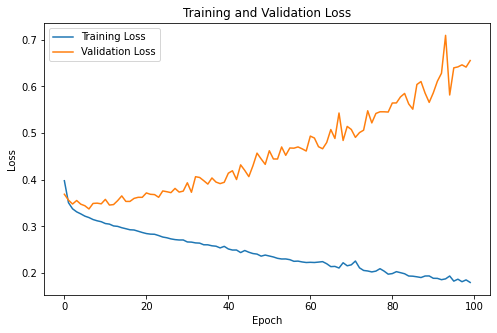

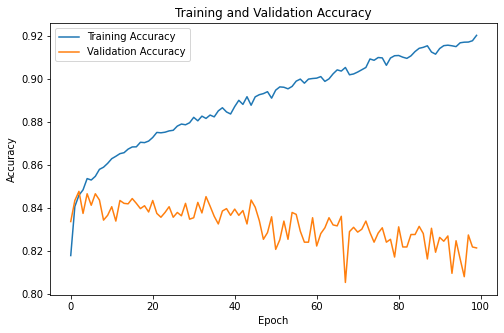

In [24]:
# Plot training loss and validation loss over epochs
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()


# Plot training accuracy and validation accuracy over epochs
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

## Model evaluation

In [25]:
# Generate predictions from your neural network using your scaled test data
# nn_model.predict() returns probabilities — apply a threshold of 0.5 to get class labels
nn_prob_predictions = nn_model.predict(X_test_scaled)
nn_class_predictions = (nn_prob_predictions >= 0.5).astype(int)



In [26]:
# Compute accuracy and F1 score for the neural network and print the results
nn_accuracy = accuracy_score(y_test, nn_class_predictions)
nn_f1 = f1_score(y_test, nn_class_predictions, average='binary')
print("Neural Network F1 Score:", nn_f1)
print("Neural Network Accuracy:", nn_accuracy)

Neural Network F1 Score: 0.6367408525084873
Neural Network Accuracy: 0.8281891168599465


1. I built a neural network with three hidden layers (64, 32, and 16 units) using ReLU activation functions to learn complex relationships in the data. The output layer uses one neuron with a sigmoid activation function because this is a binary classification problem. I chose a learning rate of 0.1 for efficient learning and trained the model for 100 epochs to allow enough time for convergence while also not making the proccess too long.
2. The training curves showed signs of overfitting. The training loss continued to decrease and the training accuracy increased throughout training, while the validation loss increased and the validation accuracy leveled off. This suggests the model learned the training data well but did not continue to improve its performance on unseen data.
3. The neural network achieved a test accuracy of 0.828 and an F1 score of 0.637. These results were slightly better than those of the Logistic Regression model, although the training curves suggested the model began to overfit as training progressed so it quite surprized me.

## Comparison of models

In [27]:
results = pd.DataFrame({
    'Metric': ['Accuracy', 'F1 Score'],
    'Logistic Regression': [final_lr_accuracy, final_lr_f1],
    'Neural Network': [nn_accuracy, nn_f1]
})

print(results.to_string(index=False))

   Metric  Logistic Regression  Neural Network
 Accuracy             0.827832        0.828189
 F1 Score             0.609154        0.636741


1. The Logistic Regression model achieved an accuracy of 0.8278 and an F1 score of 0.6092, while the Neural Network achieved an accuracy of 0.8282 and an F1 score of 0.6367. The accuracy of the two models was nearly identical, but the neural network produced a higher F1 score, indicating that it was better at identifying high-priced listings while maintaining a balance between precision and recall.
2. Although the Neural Network showed signs of overfitting in the training curves, it still generalized well on the test set and achieved the higher F1 score. Because of this, I would recommend the Neural Network if improving prediction of high-priced listings is the priority. However, Logistic Regression remains a strong alternative because it is simpler, easier to interpret, and trains much faster.
3. If I were presenting these results to the client, I would recommend deploying the Neural Network. While Logistic Regression is easier to interpret and trains more quickly, the neural network performed better on the metric that is most important for identifying the less common high-priced listings. This improved performance could help the client make more accurate pricing decisions.
4. If I had more time, I would experiment with different neural network architectures, such as changing the number of hidden layers or units, tuning the learning rate and number of epochs, and using techniques like early stopping or dropout to reduce overfitting. I would also explore additional feature engineering and methods for handling class imbalance to further improve model performance.
